# 03 - Forecasting the Spanish day-ahead price

Question: using only what is known at 12:00 on D-1, can we forecast the 24 hourly prices of day D better than a naive rule, and by how much?

Set-up (all functions are in `src/forecast.py`, tested in `tests/test_no_leakage.py`):

| Known at 12:00 on D-1 | Not known (never used) |
|---|---|
| Prices of D-1 and earlier (published on D-2) | Any realised value of day D |
| TSO day-ahead **load** forecast for D | Gas / carbon close of D-1 (set after noon) |
| Gas and carbon closes of D-2 and earlier | |
| Calendar (hour, weekday, holiday) | |

The TSO **wind and solar** forecasts may be published up to 18:00 on D-1 (Reg. EU 543/2013, art. 14), after the gate closure. They are tested separately (`_ws` models): the gap between the two versions measures how much the result depends on that assumption.

Protocol: expanding-window walk-forward by month (train on all days before the month, forecast the month, slide). Hyper-parameters are chosen on the last 28 days of each *training* window; the test month is never used to fit or to select. The feature set and the hyper-parameter grids were fixed before the first run and not changed afterwards.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

sys.path.insert(0, str(Path("..") / "src"))
import forecast as F

RAW = Path("..") / "data" / "raw"
PROCESSED = Path("..") / "data" / "processed"
FIGURES = Path("..") / "figures"
FIGURES.mkdir(exist_ok=True)

# Colours: categorical slots 1, 2, 7 of the reference palette (checked for colour-blind separation); grey = naive reference
GREY, BLUE, ORANGE, VIOLET = "#7a7a76", "#2a78d6", "#eb6834", "#6250d6"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
                     "lines.linewidth": 2, "font.size": 10})

## 1. Build the dataset

In [2]:
hourly = pd.read_parquet(PROCESSED / "ES_hourly_2024.parquet")
fuels = F.load_fuels(RAW)
ds = F.build_dataset(hourly, fuels)

print("rows:", len(ds), "| from", ds.index.min(), "to", ds.index.max())
print("missing values per feature:")
print(ds[F.FEATURES_WS].isna().sum()[lambda s: s > 0].to_string())
print("days with a missing TSO forecast:", sorted({str(d.date()) for d in F.local_date(ds.index[ds[['solar_fc','wind_fc']].isna().any(axis=1)])}))

rows: 8616 | from 2024-01-08 00:00:00+01:00 to 2024-12-31 23:00:00+01:00
missing values per feature:
solar_fc    120
wind_fc      24
res_fc      144
days with a missing TSO forecast: ['2024-06-02', '2024-12-07', '2024-12-08', '2024-12-09', '2024-12-10', '2024-12-11']


One row, to check by eye what the model sees for the forecast of a given hour (here 18:00 on Tuesday 10 September 2024; compare with the raw data):

In [3]:
t = pd.Timestamp("2024-09-10 18:00", tz="Europe/Madrid")
row = ds.loc[t, ["price"] + F.FEATURES_WS]
print(row.round(2).to_string())
print("\nSame hour D-1 (lag_24) in the raw data:", hourly.loc[t - pd.Timedelta(hours=24), "price"])
# D = Tuesday 10 Sep: D-2 is Sunday 8 Sep (no trading), so the last close dated D-2 or earlier is Friday 6 Sep
print("TTF close of Fri 6 Sep in the raw file:", round(fuels.loc["2024-09-06", "ttf"], 2), "| TTF in the row above:", round(row["ttf"], 2))
print("The closes dated D-1 (Mon 9 Sep) and later are not used.")

price                53.10
lag_24               71.94
lag_48                3.32
lag_168             101.92
prev_day_mean        86.54
prev_day_min          6.12
prev_day_max        132.00
prev_week_mean       89.74
load_fc           29646.25
ttf                  36.48
eua                  66.50
mc                   99.82
hour                 18.00
dow                   1.00
holiday               0.00
solar_fc          14376.75
wind_fc            6438.50
res_fc             8831.00

Same hour D-1 (lag_24) in the raw data: 71.94
TTF close of Fri 6 Sep in the raw file: 36.48 | TTF in the row above: 36.48
The closes dated D-1 (Mon 9 Sep) and later are not used.


## 2. Baselines and models, walk-forward

- `naive_d1`: price of the same hour yesterday.
- `naive_d7`: same hour, same weekday last week.
- `naive_weekly`: `naive_d1` for Tuesday to Friday, `naive_d7` for Saturday to Monday (the usual benchmark in the price-forecasting literature).
- `ridge`, `hgb` (gradient boosting, scikit-learn `HistGradientBoostingRegressor`): features known at noon D-1.
- `ridge_ws`, `hgb_ws`: same, plus TSO wind, solar and residual-load forecasts.

In [4]:
folds = F.monthly_folds(ds)                       # 9 test months: April to December 2024
base = F.baselines(ds)

specs = {"ridge": (F.FEATURES_BASE, "ridge"), "hgb": (F.FEATURES_BASE, "hgb"),
         "ridge_ws": (F.FEATURES_WS, "ridge"), "hgb_ws": (F.FEATURES_WS, "hgb")}
models, chosen = {}, {}
for name, (feats, kind) in specs.items():
    models[name], chosen[name] = F.walk_forward(ds, feats, kind, folds)

preds_all = pd.concat([base, pd.DataFrame(models)], axis=1)
chosen["hgb_ws"].round(3)

,test_month,max_iter,max_leaf_nodes,inner_val_mae
0,2024-04,150,8,16.647
1,2024-05,150,31,8.641
2,2024-06,400,8,10.980
3,2024-07,400,31,16.959
4,2024-08,150,31,12.377
5,2024-09,400,31,11.892
6,2024-10,150,8,11.699
7,2024-11,150,31,12.959
8,2024-12,400,8,15.973


In [5]:
# Evaluate every model on the same rows: test months, and no missing TSO forecast
in_test = np.any([f.test for f in folds], axis=0)
complete = ds[F.FEATURES_WS].notna().all(axis=1).to_numpy()
ok = in_test & complete
y = ds.loc[ok, "price"]
preds = preds_all[ok]
print(f"{ok.sum()} hourly forecasts evaluated ({ok.sum() // 24} days); {in_test.sum() - ok.sum()} hours excluded for a missing TSO forecast")

6457 hourly forecasts evaluated (269 days); 144 hours excluded for a missing TSO forecast


## 3. Results

In [6]:
res = F.scores(y, preds, ref="naive_d1")
res = res.rename(columns={"rMAE": "MAE / MAE(naive_d1)"})

# Diebold-Mariano: is the daily MAE of each model lower than naive_d1's? (negative statistic: model better)
daily = {c: F.daily_abs_error(y, preds[c]) for c in preds.columns}
dm = {c: F.diebold_mariano(daily[c], daily["naive_d1"]) for c in preds.columns if c != "naive_d1"}
res["DM stat vs naive_d1"] = pd.Series({c: v[0] for c, v in dm.items()})
res["DM p-value"] = pd.Series({c: v[1] for c, v in dm.items()})
res.round(3)

,MAE,RMSE,MAE / MAE(naive_d1),DM stat vs naive_d1,DM p-value
naive_d1,19.140,28.446,1.000,NaN,NaN
naive_d7,27.482,38.465,1.436,4.642,0.000
naive_weekly,21.944,32.709,1.146,2.106,0.035
ridge,18.359,24.058,0.959,-1.147,0.251
hgb,19.099,24.819,0.998,-0.056,0.955
ridge_ws,14.431,19.051,0.754,-5.249,0.000
hgb_ws,13.420,17.701,0.701,-5.905,0.000


In [7]:
# Direct comparisons between models (same test)
pairs = [("hgb", "ridge"), ("hgb_ws", "ridge_ws"), ("hgb_ws", "hgb"), ("ridge_ws", "ridge")]
pd.DataFrame(
    [{"A": a, "B": b, "MAE A": daily[a].mean(), "MAE B": daily[b].mean(),
      "DM stat": F.diebold_mariano(daily[a], daily[b])[0], "p-value": F.diebold_mariano(daily[a], daily[b])[1]}
     for a, b in pairs]
).round(3)

,A,B,MAE A,MAE B,DM stat,p-value
0,hgb,ridge,19.096,18.357,1.441,0.149
1,hgb_ws,ridge_ws,13.420,14.432,-2.375,0.018
2,hgb_ws,hgb,13.420,19.096,-7.860,0.000
3,ridge_ws,ridge,14.432,18.357,-7.466,0.000


### By month and by time of day

In [8]:
month = F.local_date(y.index).to_period("M")
by_month = (y - preds.T).abs().T.groupby(month).mean()[["naive_d1", "naive_weekly", "ridge", "hgb", "ridge_ws", "hgb_ws"]]
by_month["price level (mean)"] = y.groupby(month).mean()
by_month.round(1)

,naive_d1,naive_weekly,ridge,hgb,ridge_ws,hgb_ws,price level (mean)
time_local,,,,,,,
2024-04,8.3,9.9,12.4,9.0,12.2,10.5,13.7
2024-05,15.0,13.9,15.4,15.3,10.9,11.5,30.4
2024-06,21.6,23.4,21.7,21.7,19.6,18.5,57.9
2024-07,18.7,16.7,16.9,18.9,14.7,12.0,72.3
2024-08,21.2,16.4,17.0,21.5,13.6,14.4,91.1
2024-09,19.7,28.4,20.2,20.3,14.3,11.6,72.6
2024-10,25.8,24.2,20.9,21.8,16.2,14.0,68.6
2024-11,23.8,27.8,23.0,24.3,15.0,17.3,104.4
2024-12,18.0,39.7,17.8,19.2,13.5,10.8,117.3


In [9]:
blocks = pd.cut(y.index.hour, [-1, 5, 11, 15, 19, 23], labels=["00-05", "06-11", "12-15", "16-19", "20-23"])
by_block = (y - preds.T).abs().T.groupby(blocks, observed=True).mean()[["naive_d1", "ridge", "hgb", "ridge_ws", "hgb_ws"]]
by_block["price level (mean)"] = y.groupby(blocks, observed=True).mean()
by_block.round(1)

,naive_d1,ridge,hgb,ridge_ws,hgb_ws,price level (mean)
00-05,17.8,18.3,19.3,14.7,14.0,73.1
06-11,22.0,18.9,19.8,14.7,14.0,70.7
12-15,19.8,18.1,17.3,14.3,12.1,40.9
16-19,19.0,18.2,18.2,13.9,12.3,61.7
20-23,16.3,18.1,20.4,14.2,14.2,96.1


### Figures

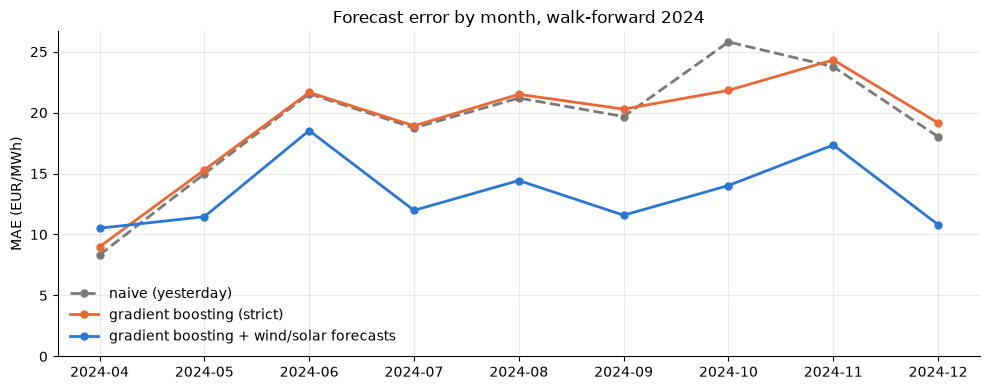

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(by_month))
ax.plot(x, by_month["naive_d1"], color=GREY, ls="--", marker="o", ms=5, label="naive (yesterday)")
ax.plot(x, by_month["hgb"], color=ORANGE, marker="o", ms=5, label="gradient boosting (strict)")
ax.plot(x, by_month["hgb_ws"], color=BLUE, marker="o", ms=5, label="gradient boosting + wind/solar forecasts")
ax.set_xticks(x, [str(p) for p in by_month.index])
ax.set_ylabel("MAE (EUR/MWh)")
ax.set_ylim(0)
ax.set_title("Forecast error by month, walk-forward 2024")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "03_mae_by_month.png", dpi=150)
plt.show()

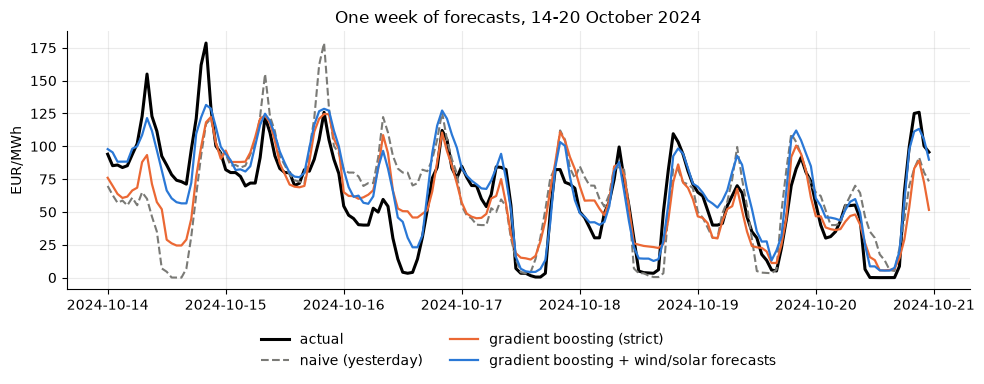

In [11]:
start, end = pd.Timestamp("2024-10-14", tz="Europe/Madrid"), pd.Timestamp("2024-10-21", tz="Europe/Madrid")
w = (preds_all.index >= start) & (preds_all.index < end)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ds.index[w], ds.loc[w, "price"], color="black", lw=2.2, label="actual")
ax.plot(ds.index[w], preds_all.loc[w, "naive_d1"], color=GREY, ls="--", lw=1.5, label="naive (yesterday)")
ax.plot(ds.index[w], preds_all.loc[w, "hgb"], color=ORANGE, lw=1.6, label="gradient boosting (strict)")
ax.plot(ds.index[w], preds_all.loc[w, "hgb_ws"], color=BLUE, lw=1.6, label="gradient boosting + wind/solar forecasts")
ax.set_ylabel("EUR/MWh")
ax.set_title("One week of forecasts, 14-20 October 2024")
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
fig.savefig(FIGURES / "03_week_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

### What the gradient-boosting model relies on
Permutation importance: shuffle one feature in the test rows and measure how much the MAE increases. Model fitted on January-September, evaluated on October-December (interpretation only: nothing here is used to choose the model).

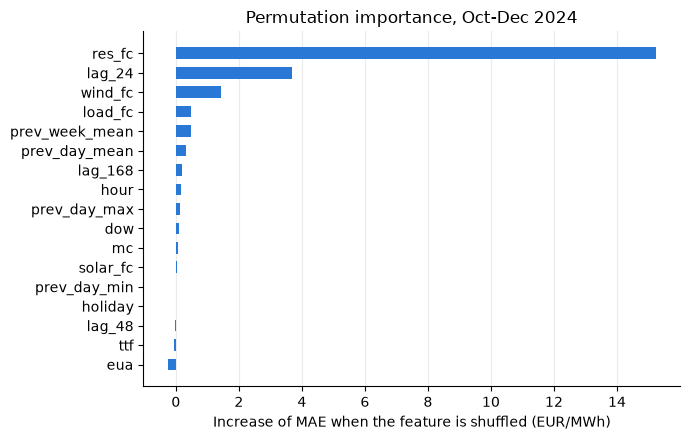

res_fc            15.23
lag_24             3.70
wind_fc            1.44
load_fc            0.49
prev_week_mean     0.49
prev_day_mean      0.32
lag_168            0.20
hour               0.16
prev_day_max       0.14
dow                0.11
mc                 0.06
solar_fc           0.03
prev_day_min       0.00
holiday            0.00
lag_48            -0.02
ttf               -0.07
eua               -0.26
dtype: float64

In [12]:
d = F.local_date(ds.index)
tr = np.asarray(d < pd.Timestamp("2024-10-01"))
te = np.asarray(d >= pd.Timestamp("2024-10-01")) & complete
params = chosen["hgb_ws"].iloc[-3][["max_iter", "max_leaf_nodes"]].astype(int).to_dict()    # parameters chosen for October
m = F._estimator("hgb", params, F.FEATURES_WS).fit(ds.loc[tr, F.FEATURES_WS], ds.loc[tr, "price"])
imp = permutation_importance(m, ds.loc[te, F.FEATURES_WS], ds.loc[te, "price"],
                             scoring="neg_mean_absolute_error", n_repeats=10, random_state=0)
imp = pd.Series(imp.importances_mean, index=F.FEATURES_WS).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(imp.index, imp.values, color=BLUE, height=0.6)
ax.set_xlabel("Increase of MAE when the feature is shuffled (EUR/MWh)")
ax.set_title("Permutation importance, Oct-Dec 2024")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "03_importance.png", dpi=150)
plt.show()
imp.sort_values(ascending=False).round(2)

In [13]:
out = preds_all.copy()
out.insert(0, "price", ds["price"])
out[in_test].to_parquet(PROCESSED / "forecasts_ES_2024.parquet")

## 4. Findings and limits

**Setting:** 9 test months (April-December 2024), 269 days, 6,457 hourly forecasts evaluated for every model on the same rows. Error in EUR/MWh; the mean price over these months is about 69.

1. **The best naive forecast is "same hour yesterday"** (MAE 19.1, RMSE 28.4). "Same day last week" is much worse (27.5) and the weekday rule `naive_weekly` is worse than yesterday here (21.9): the weekly pattern is not strong enough to justify using last week for Saturday to Monday.
2. **Without wind and solar forecasts, the models barely beat the naive forecast on MAE.** Gradient boosting: MAE 18.1 (-5 %), ridge: 18.2 (-5 %). The difference is not statistically significant (Diebold-Mariano on daily MAE, p = 0.15 and 0.17), and it is better in only 5 of the 9 months. RMSE improves more (23.8 vs 28.4, -16 %): the models mostly reduce large errors. Gradient boosting and ridge are indistinguishable here (p = 0.80).
3. **The wind / solar forecast is what brings the gain.** With it, gradient boosting reaches MAE 14.2 (-26 % vs naive, p < 0.001) and RMSE 18.5 (-35 %); ridge reaches 15.4. It beats the naive forecast in 8 of the 9 months (not in April, the month with the lowest prices). Among the models with the wind / solar forecast, gradient boosting is better than ridge (p < 0.001), consistent with a non-linear link between price and residual load.
4. **Where:** the strict models are better than naive at midday (12-15 h: MAE 16.8 vs 19.8) but worse in the evening (20-23 h: 19.0 vs 16.3), when the price follows the gas-fired ramp. With the wind/solar forecast they win in every time block.
5. **What the model uses** (permutation importance, Oct-Dec): the forecast residual load by far (+11.8 EUR/MWh of MAE when shuffled), then yesterday's price (+3.8), then the wind forecast (+1.4). TTF and the marginal cost contribute about nothing once these are known. The EUA ranks fourth (+0.6) but it moves slowly over a single year and can act as a time index: this is not evidence of a carbon effect on the hourly price.

**Limits**

- **The wind / solar forecast is the weak point of the protocol.** The TSO may publish it until 18:00 on D-1, after the gate closure, and the value stored on ENTSO-E is the last published one (possibly updated after noon). The `_ws` results are therefore an optimistic bound; the strict results are the conservative ones. A trader would use their own or a vendor's forecast of equal or better quality at noon.
- One year, one market, nine monthly tests: no 2022-2023 regime, no crisis. The 2024 data are the only ones used for training and testing; results on another year may differ.
- Point forecasts only. No probabilistic forecast, no trading strategy, no P&L: a lower MAE does not by itself mean a profitable signal, in particular because prices at about 0 EUR/MWh and spikes are not weighted by their economic value.
- Diebold-Mariano tests on 269 daily losses: normal approximation, no correction for the number of comparisons.
- Small hyper-parameter grids (4 settings per model); selection on the last 28 days of each training window is noisy (the chosen settings change from month to month, see the table above).
- Gas is TTF, not MIBGAS; fuel prices are those of D-2 (a conservative reading of the timing).
- The six days with a missing TSO forecast are not evaluated; they stay in the training windows (the gradient boosting handles missing values, ridge imputes the median).
- This is research code, not a production system: no live data pipeline, no monitoring. Only the absence of look-ahead is tested (`tests/test_no_leakage.py`).